# CNN-Transformer Final: End-to-End Pipeline

Proper training and evaluation of CNN-Transformer for single-lead ECG MI detection.
Fixes the validation leak from earlier notebooks by using a 3-way stratified split.

### Pipeline:
1. Data loading with proper splits (PTB-XL folds + Shaoxing 40/20/40)
2. Pre-train on PTB-XL (100 epochs, patience 15)
3. Zero-shot evaluation on full Shaoxing
4. Fine-tune on Shaoxing train (50 epochs, patience 10)
5. Threshold optimization on Shaoxing validation
6. Final evaluation on Shaoxing test (touched once)
7. ONNX export
8. Qualcomm AI Hub compile + profile
9. Final report

### Key difference from earlier notebooks:
- Shaoxing split: 40% train / 20% validation / 40% test (stratified)
- Model selection and threshold tuning use validation set only
- Test set evaluated once at the end

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from tqdm import tqdm
from sklearn.metrics import roc_auc_score, precision_recall_curve, f1_score, classification_report
from sklearn.model_selection import train_test_split
import wfdb
import ast
import duckdb
from datetime import datetime
import time

device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
print(f"Using device: {device}")

os.makedirs("../checkpoints", exist_ok=True)
os.makedirs("../models", exist_ok=True)
os.makedirs("../cache", exist_ok=True)

db = duckdb.connect("../experiment_results.duckdb")
db.execute("""
    CREATE TABLE IF NOT EXISTS catnet_final (
        timestamp TIMESTAMP, stage VARCHAR, epoch INTEGER,
        train_loss DOUBLE, train_auc DOUBLE,
        val_loss DOUBLE, val_auc DOUBLE,
        notes VARCHAR
    )
""")
db.execute("""
    CREATE TABLE IF NOT EXISTS catnet_final_results (
        timestamp TIMESTAMP, metric VARCHAR, value DOUBLE, notes VARCHAR
    )
""")
print("Ready.")

Using device: mps
Ready.


## 1. Data Loading

In [2]:
# --- PTB-XL ---
ptb_path = '../data/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/'

def load_ptbxl_data(path):
    df = pd.read_csv(os.path.join(path, 'ptbxl_database.csv'), index_col=0)
    df.scp_codes = df.scp_codes.apply(lambda x: ast.literal_eval(x))
    return df

def aggregate_diagnostic(y_dic, agg_df):
    tmp = []
    for key in y_dic.keys():
        if key in agg_df.index: tmp.append(agg_df.loc[key].diagnostic_class)
    return list(set(tmp))

agg_df = pd.read_csv(os.path.join(ptb_path, 'scp_statements.csv'), index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]
df = load_ptbxl_data(ptb_path)
df['diagnostic_class'] = df.scp_codes.apply(aggregate_diagnostic, agg_df=agg_df)
df['MI'] = df.diagnostic_class.apply(lambda x: 1 if 'MI' in x else 0)

ptb_train_df = df[df.strat_fold < 9]
ptb_val_df = df[df.strat_fold == 9]
ptb_test_df = df[df.strat_fold == 10]

print(f"PTB-XL — Train: {len(ptb_train_df)} | Val: {len(ptb_val_df)} | Test: {len(ptb_test_df)}")
print(f"  MI prevalence: {df.MI.mean()*100:.2f}%")

PTB-XL — Train: 17418 | Val: 2183 | Test: 2198
  MI prevalence: 25.09%


In [3]:
# --- Shaoxing (full, with pre-scanned labels) ---
shaoxing_path = '../data/a-large-scale-12-lead-electrocardiogram-database-for-arrhythmia-study-1.0.0/'
MI_CODE = '164865005'

class ShaoxingDataset(Dataset):
    def __init__(self, base_path, lead_idx=0):
        self.base_path = base_path
        self.lead_idx = lead_idx
        self.records = []
        with open(os.path.join(base_path, 'RECORDS'), 'r') as f:
            subfolders = [line.strip() for line in f if line.strip()]
        for sub in subfolders:
            sub_path = os.path.join(base_path, sub)
            if os.path.exists(sub_path):
                for fname in os.listdir(sub_path):
                    if fname.endswith('.hea'):
                        self.records.append(os.path.join(sub, fname.replace('.hea', '')))
        self.labels = []
        print(f"Scanning labels for {len(self.records)} Shaoxing records...")
        for rec in tqdm(self.records, desc="Labels"):
            try:
                _, meta = wfdb.rdsamp(os.path.join(base_path, rec))
                dx_list = []
                for c in meta['comments']:
                    if 'Dx:' in c:
                        dx_list = [x.strip() for x in c.split('Dx:')[1].strip().split(',')]
                        break
                self.labels.append(1 if MI_CODE in dx_list else 0)
            except:
                self.labels.append(0)
        print(f"Total: {len(self.records)} | MI: {sum(self.labels)} ({sum(self.labels)/len(self.labels)*100:.2f}%)")

    def __len__(self): return len(self.records)

    def __getitem__(self, idx):
        try:
            signal, _ = wfdb.rdsamp(os.path.join(self.base_path, self.records[idx]))
            s = signal[::5, self.lead_idx].astype(np.float32)
            s = (s - s.mean()) / (s.std() + 1e-8)
            return torch.tensor(s, dtype=torch.float32).unsqueeze(0), torch.tensor(self.labels[idx], dtype=torch.float32)
        except:
            return torch.zeros(1, 1000), torch.tensor(0, dtype=torch.float32)

shaoxing_full = ShaoxingDataset(shaoxing_path)

Scanning labels for 45152 Shaoxing records...


Labels: 100%|██████████| 45152/45152 [02:05<00:00, 359.36it/s]

Total: 45152 | MI: 123 (0.27%)


In [4]:
# --- 40/20/40 stratified split ---
shao_labels = np.array(shaoxing_full.labels)
indices = np.arange(len(shaoxing_full))

# First split: 40% train, 60% remainder
train_idx, remaining_idx = train_test_split(
    indices, test_size=0.6, stratify=shao_labels, random_state=42)

# Second split: split remainder into 20% val, 40% test (i.e., 1/3 and 2/3 of remainder)
remaining_labels = shao_labels[remaining_idx]
val_idx, test_idx = train_test_split(
    remaining_idx, test_size=2/3, stratify=remaining_labels, random_state=42)

shao_train = Subset(shaoxing_full, train_idx)
shao_val = Subset(shaoxing_full, val_idx)
shao_test = Subset(shaoxing_full, test_idx)

print(f"Shaoxing splits:")
print(f"  Train: {len(shao_train):6d} (MI: {shao_labels[train_idx].sum()})")
print(f"  Val:   {len(shao_val):6d} (MI: {shao_labels[val_idx].sum()})")
print(f"  Test:  {len(shao_test):6d} (MI: {shao_labels[test_idx].sum()})")

# Save splits for reproducibility
split_df = pd.DataFrame({
    'index': indices,
    'record': [shaoxing_full.records[i] for i in indices],
    'mi_label': shao_labels,
})
split_df['split'] = 'none'
split_df.loc[split_df['index'].isin(train_idx), 'split'] = 'train'
split_df.loc[split_df['index'].isin(val_idx), 'split'] = 'val'
split_df.loc[split_df['index'].isin(test_idx), 'split'] = 'test'
split_df.to_csv('../data/shaoxing_final_splits.csv', index=False)
print("\nSaved splits to data/shaoxing_final_splits.csv")

Shaoxing splits:
  Train:  18060 (MI: 49)
  Val:     9030 (MI: 25)
  Test:   18062 (MI: 49)

Saved splits to data/shaoxing_final_splits.csv


In [5]:
# --- Augmented PTB-XL dataset ---
class AugmentedPTBXLDataset(Dataset):
    def __init__(self, df, base_path, lead_idx=0, augment=True):
        self.df = df
        self.base_path = base_path
        self.lead_idx = lead_idx
        self.augment = augment
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        filename = os.path.join(self.base_path, self.df.iloc[idx].filename_lr)
        signal, _ = wfdb.rdsamp(filename)
        s = signal[:, self.lead_idx].astype(np.float32)
        if self.augment:
            if np.random.random() < 0.5: s += np.random.normal(0, 0.02, s.shape).astype(np.float32)
            if np.random.random() < 0.5: s *= np.random.uniform(0.8, 1.2)
            if np.random.random() < 0.3: s = np.roll(s, np.random.randint(-50, 50))
        s = (s - s.mean()) / (s.std() + 1e-8)
        return torch.tensor(s, dtype=torch.float32).unsqueeze(0), torch.tensor(self.df.iloc[idx].MI, dtype=torch.float32)

## 2. Model & Training Utilities

In [6]:
class CATNet(nn.Module):
    def __init__(self, num_classes=1, d_model=64, nhead=4, num_encoder_layers=2):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=5, stride=2, padding=2, bias=False),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, d_model, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm1d(d_model), nn.ReLU(),
        )
        self.pos_embed = nn.Parameter(torch.zeros(1, 125, d_model))
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model*4,
            dropout=0.1, batch_first=True, activation='gelu')
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_encoder_layers)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Linear(d_model, num_classes)
    def forward(self, x):
        x = self.cnn(x).transpose(1, 2)
        x = x + self.pos_embed[:, :x.size(1), :]
        x = self.transformer(x).transpose(1, 2)
        return self.head(self.pool(x).squeeze(-1))

class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        pt = torch.exp(-bce)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt) ** self.gamma * bce).mean()

def get_predictions(loader, model, dev):
    """Get all predictions and targets from a loader."""
    model.eval()
    all_logits, all_targets = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(dev)
            out = model(x).squeeze()
            if out.dim() == 0: out = out.unsqueeze(0)
            all_logits.extend(out.cpu().numpy())
            all_targets.extend(y.numpy())
    logits = np.array(all_logits)
    targets = np.array(all_targets)
    probs = 1 / (1 + np.exp(-logits))
    return logits, probs, targets

def evaluate(loader, model, criterion, dev):
    _, probs, targets = get_predictions(loader, model, dev)
    loss_fn = criterion
    # Recompute loss
    model.eval()
    losses = []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            out = model(x).squeeze()
            if out.dim() == 0: out = out.unsqueeze(0)
            losses.append(loss_fn(out, y).item())
    auc = roc_auc_score(targets, probs) if len(set(targets.astype(int))) > 1 else 0.5
    return np.mean(losses), auc

def train_epoch(loader, model, criterion, optimizer, dev):
    model.train()
    losses, preds, targets = [], [], []
    for x, y in loader:
        x, y = x.to(dev), y.to(dev)
        optimizer.zero_grad()
        out = model(x).squeeze()
        if out.dim() == 0: out = out.unsqueeze(0)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        preds.extend(torch.sigmoid(out).detach().cpu().numpy())
        targets.extend(y.detach().cpu().numpy())
    auc = roc_auc_score(targets, preds) if len(set([int(t) for t in targets])) > 1 else 0.5
    return np.mean(losses), auc

print(f"CNN-Transformer: {sum(p.numel() for p in CATNet().parameters()):,} params")

CNN-Transformer: 131,105 params


## 3. Pre-train on PTB-XL

In [7]:
batch_size = 64
lr = 1e-3
warmup_epochs = 5
pretrain_max = 100
pretrain_patience = 15

train_loader = DataLoader(AugmentedPTBXLDataset(ptb_train_df, ptb_path, augment=True), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(AugmentedPTBXLDataset(ptb_val_df, ptb_path, augment=False), batch_size=batch_size)

model = CATNet().to(device)
criterion = FocalLoss(alpha=0.25, gamma=2.0)
optimizer = optim.Adam(model.parameters(), lr=lr)

def lr_lambda(epoch):
    if epoch < warmup_epochs:
        return (epoch + 1) / warmup_epochs
    cos_epoch = epoch - warmup_epochs
    cos_max = pretrain_max - warmup_epochs
    return 0.5 * (1 + np.cos(np.pi * cos_epoch / cos_max))
scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

best_val_auc = 0
patience = 0
pretrain_history = {'train_loss': [], 'val_loss': [], 'train_auc': [], 'val_auc': []}

print(f"Pre-training on PTB-XL ({len(ptb_train_df)} samples, up to {pretrain_max} epochs, patience {pretrain_patience})")
print(f"Hyperparameters: lr={lr}, warmup={warmup_epochs}, batch_size={batch_size}\n")

for epoch in range(pretrain_max):
    t_loss, t_auc = train_epoch(train_loader, model, criterion, optimizer, device)
    v_loss, v_auc = evaluate(val_loader, model, criterion, device)
    scheduler.step()
    
    pretrain_history['train_loss'].append(t_loss)
    pretrain_history['val_loss'].append(v_loss)
    pretrain_history['train_auc'].append(t_auc)
    pretrain_history['val_auc'].append(v_auc)
    
    if v_auc > best_val_auc:
        best_val_auc = v_auc
        patience = 0
        torch.save({'model_state_dict': model.state_dict(), 'epoch': epoch+1, 'val_auc': v_auc},
                   '../checkpoints/cnn_transformer_final_pretrained_best.pt')
    else:
        patience += 1
    
    if (epoch + 1) % 5 == 0 or epoch == 0 or patience >= pretrain_patience:
        print(f"  Epoch {epoch+1:3d}: T-AUC {t_auc:.4f} | V-AUC {v_auc:.4f} (best: {best_val_auc:.4f}, patience: {patience})")
    
    db.execute("INSERT INTO catnet_final VALUES (?, ?, ?, ?, ?, ?, ?, ?)",
        [datetime.now(), 'pretrain', epoch+1, t_loss, t_auc, v_loss, v_auc, f'lr={lr}, warmup={warmup_epochs}'])
    
    if patience >= pretrain_patience:
        print(f"  Early stop at epoch {epoch+1}")
        break

print(f"\nBest pre-train V-AUC: {best_val_auc:.4f}")

Pre-training on PTB-XL (17418 samples, up to 100 epochs, patience 15)
Hyperparameters: lr=0.001, warmup=5, batch_size=64

  Epoch   1: T-AUC 0.7136 | V-AUC 0.7615 (best: 0.7615, patience: 0)
  Epoch   5: T-AUC 0.7621 | V-AUC 0.7773 (best: 0.7858, patience: 2)
  Epoch  10: T-AUC 0.7892 | V-AUC 0.7912 (best: 0.7912, patience: 0)
  Epoch  15: T-AUC 0.8025 | V-AUC 0.7797 (best: 0.7912, patience: 5)
  Epoch  20: T-AUC 0.8116 | V-AUC 0.7820 (best: 0.7912, patience: 10)
  Epoch  25: T-AUC 0.8220 | V-AUC 0.7761 (best: 0.7912, patience: 15)
  Early stop at epoch 25

Best pre-train V-AUC: 0.7912


## 4. Zero-Shot Evaluation

In [8]:
# Load best pre-trained
ckpt = torch.load('../checkpoints/cnn_transformer_final_pretrained_best.pt', map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
print(f"Loaded best pre-trained model (epoch {ckpt['epoch']}, V-AUC {ckpt['val_auc']:.4f})")

# Zero-shot on all Shaoxing
full_loader = DataLoader(shaoxing_full, batch_size=batch_size)
_, zeroshot_auc = evaluate(full_loader, model, criterion, device)
print(f"Zero-shot AUC (all Shaoxing, n={len(shaoxing_full)}): {zeroshot_auc:.4f}")

# Zero-shot on each split
for name, subset in [('train', shao_train), ('val', shao_val), ('test', shao_test)]:
    loader = DataLoader(subset, batch_size=batch_size)
    _, auc = evaluate(loader, model, criterion, device)
    print(f"  {name}: AUC {auc:.4f} (n={len(subset)})")

db.execute("INSERT INTO catnet_final_results VALUES (?, ?, ?, ?)",
    [datetime.now(), 'zeroshot_auc', zeroshot_auc, f'n={len(shaoxing_full)}'])

Loaded best pre-trained model (epoch 10, V-AUC 0.7912)
Zero-shot AUC (all Shaoxing, n=45152): 0.8137
  train: AUC 0.8192 (n=18060)
  val: AUC 0.8552 (n=9030)
  test: AUC 0.7867 (n=18062)


## 5. Fine-tune on Shaoxing Train, Select on Validation

In [9]:
finetune_max = 50
finetune_patience = 10
ft_lr = lr * 0.1

# Unfreeze all
for param in model.parameters():
    param.requires_grad = True

ft_optimizer = optim.Adam(model.parameters(), lr=ft_lr)

def ft_lr_lambda(epoch):
    if epoch < warmup_epochs:
        return (epoch + 1) / warmup_epochs
    cos_epoch = epoch - warmup_epochs
    cos_max = finetune_max - warmup_epochs
    return 0.5 * (1 + np.cos(np.pi * cos_epoch / cos_max))
ft_scheduler = optim.lr_scheduler.LambdaLR(ft_optimizer, ft_lr_lambda)

shao_train_loader = DataLoader(shao_train, batch_size=batch_size, shuffle=True)
shao_val_loader = DataLoader(shao_val, batch_size=batch_size)

best_ft_auc = 0
ft_patience = 0

print(f"Fine-tuning on Shaoxing train ({len(shao_train)} samples, up to {finetune_max} epochs, patience {finetune_patience})")
print(f"  MI in train: {shao_labels[train_idx].sum()} | MI in val: {shao_labels[val_idx].sum()}")
print(f"  Model selection on VALIDATION set (not test)\n")

for epoch in range(finetune_max):
    t_loss, t_auc = train_epoch(shao_train_loader, model, criterion, ft_optimizer, device)
    v_loss, v_auc = evaluate(shao_val_loader, model, criterion, device)
    ft_scheduler.step()
    
    if v_auc > best_ft_auc:
        best_ft_auc = v_auc
        ft_patience = 0
        torch.save({'model_state_dict': model.state_dict(), 'epoch': epoch+1, 'val_auc': v_auc},
                   '../checkpoints/cnn_transformer_final_finetuned_best.pt')
    else:
        ft_patience += 1
    
    if (epoch + 1) % 5 == 0 or epoch == 0 or ft_patience >= finetune_patience:
        print(f"  Epoch {epoch+1:3d}: T-AUC {t_auc:.4f} | V-AUC {v_auc:.4f} (best: {best_ft_auc:.4f}, patience: {ft_patience})")
    
    db.execute("INSERT INTO catnet_final VALUES (?, ?, ?, ?, ?, ?, ?, ?)",
        [datetime.now(), 'finetune', epoch+1, t_loss, t_auc, v_loss, v_auc, f'ft_lr={ft_lr}'])
    
    if ft_patience >= finetune_patience:
        print(f"  Early stop at epoch {epoch+1}")
        break

print(f"\nBest fine-tune V-AUC (validation): {best_ft_auc:.4f}")

Fine-tuning on Shaoxing train (18060 samples, up to 50 epochs, patience 10)
  MI in train: 49 | MI in val: 25
  Model selection on VALIDATION set (not test)

  Epoch   1: T-AUC 0.7277 | V-AUC 0.8453 (best: 0.8453, patience: 0)
  Epoch   5: T-AUC 0.8316 | V-AUC 0.8601 (best: 0.8601, patience: 0)
  Epoch  10: T-AUC 0.9203 | V-AUC 0.8317 (best: 0.8601, patience: 5)
  Epoch  15: T-AUC 0.9848 | V-AUC 0.7643 (best: 0.8601, patience: 10)
  Early stop at epoch 15

Best fine-tune V-AUC (validation): 0.8601


## 6. Threshold Optimization (on Validation Set)

In [10]:
# Load best fine-tuned model
ckpt = torch.load('../checkpoints/cnn_transformer_final_finetuned_best.pt', map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
print(f"Loaded best fine-tuned model (epoch {ckpt['epoch']}, V-AUC {ckpt['val_auc']:.4f})")

# Get predictions on validation set
val_logits, val_probs, val_targets = get_predictions(shao_val_loader, model, device)

print(f"\nValidation set: {len(val_targets)} samples, {int(val_targets.sum())} MI")
print(f"Prediction distribution:")
print(f"  All    — mean: {val_probs.mean():.4f}, median: {np.median(val_probs):.4f}, max: {val_probs.max():.4f}")
print(f"  MI     — mean: {val_probs[val_targets==1].mean():.4f}, min: {val_probs[val_targets==1].min():.4f}, max: {val_probs[val_targets==1].max():.4f}")
print(f"  Non-MI — mean: {val_probs[val_targets==0].mean():.4f}")

Loaded best fine-tuned model (epoch 5, V-AUC 0.8601)

Validation set: 9030 samples, 25 MI
Prediction distribution:
  All    — mean: 0.0576, median: 0.0505, max: 0.3627
  MI     — mean: 0.1114, min: 0.0346, max: 0.2422
  Non-MI — mean: 0.0574


Best F1 threshold: 0.2022
  F1=0.1053, Precision=0.0938, Recall=0.1200

90% recall threshold: 0.0564
  Precision=0.0070, Recall=0.9200

Youden's J threshold: 0.0803
  Sensitivity=0.7600, Specificity=0.8854


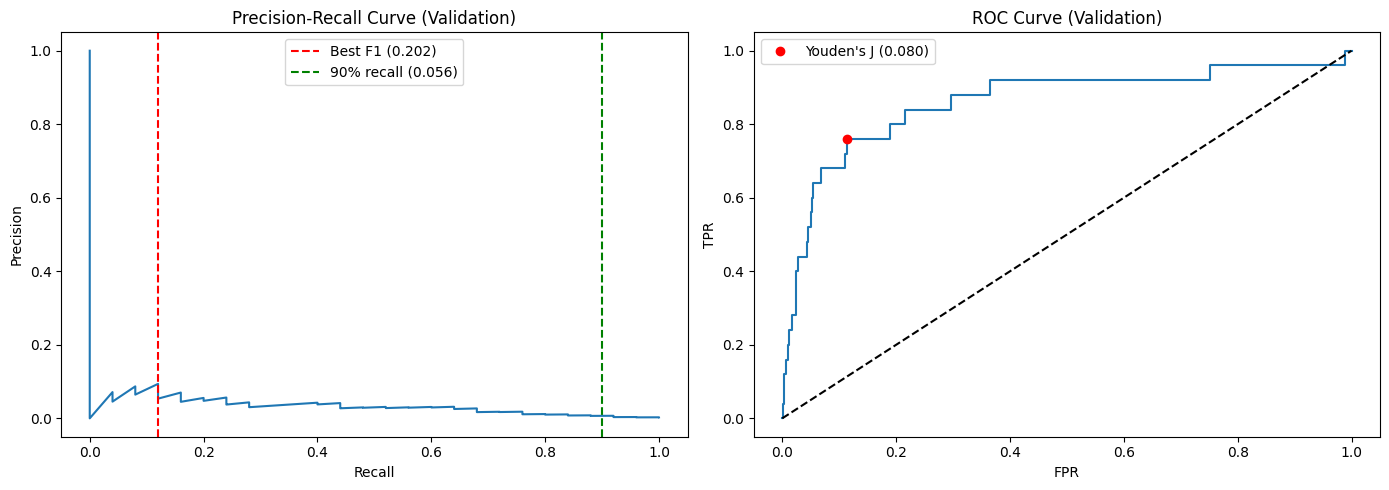


Chosen thresholds: {'best_f1': np.float32(0.20222214), 'youden': np.float32(0.08031028), 'recall_90': np.float32(0.056437116)}


In [11]:
# Find optimal thresholds
precisions, recalls, thresholds = precision_recall_curve(val_targets, val_probs)

# Threshold for best F1
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-8)
best_f1_idx = np.argmax(f1_scores)
thresh_f1 = thresholds[best_f1_idx]
print(f"Best F1 threshold: {thresh_f1:.4f}")
print(f"  F1={f1_scores[best_f1_idx]:.4f}, Precision={precisions[best_f1_idx]:.4f}, Recall={recalls[best_f1_idx]:.4f}")

# Threshold for 90% recall (screening use case)
recall_target = 0.90
valid_mask = recalls[:-1] >= recall_target  # last element of recalls is 0
if valid_mask.any():
    # Among thresholds achieving >= 90% recall, pick the one with best precision
    candidates = np.where(valid_mask)[0]
    best_prec_idx = candidates[np.argmax(precisions[:-1][valid_mask])]
    thresh_90recall = thresholds[best_prec_idx]
    print(f"\n90% recall threshold: {thresh_90recall:.4f}")
    print(f"  Precision={precisions[best_prec_idx]:.4f}, Recall={recalls[best_prec_idx]:.4f}")
else:
    thresh_90recall = None
    print("\nCannot achieve 90% recall on validation set.")

# Threshold for Youden's J (sensitivity + specificity - 1)
from sklearn.metrics import roc_curve
fpr, tpr, roc_thresholds = roc_curve(val_targets, val_probs)
youdens_j = tpr - fpr
best_j_idx = np.argmax(youdens_j)
thresh_youden = roc_thresholds[best_j_idx]
print(f"\nYouden's J threshold: {thresh_youden:.4f}")
print(f"  Sensitivity={tpr[best_j_idx]:.4f}, Specificity={1-fpr[best_j_idx]:.4f}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(recalls, precisions)
axes[0].axvline(x=recalls[best_f1_idx], color='r', linestyle='--', label=f'Best F1 ({thresh_f1:.3f})')
if thresh_90recall is not None:
    axes[0].axvline(x=0.9, color='g', linestyle='--', label=f'90% recall ({thresh_90recall:.3f})')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curve (Validation)')
axes[0].legend()

axes[1].plot(fpr, tpr)
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].plot(fpr[best_j_idx], tpr[best_j_idx], 'ro', label=f"Youden's J ({thresh_youden:.3f})")
axes[1].set_xlabel('FPR')
axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve (Validation)')
axes[1].legend()

plt.tight_layout()
plt.show()

# Store thresholds
chosen_thresholds = {
    'best_f1': thresh_f1,
    'youden': thresh_youden,
}
if thresh_90recall is not None:
    chosen_thresholds['recall_90'] = thresh_90recall

print(f"\nChosen thresholds: {chosen_thresholds}")

## 7. Final Evaluation on Test Set (One Time Only)

In [12]:
# THIS CELL EVALUATES ON THE TEST SET — RUN ONLY ONCE
shao_test_loader = DataLoader(shao_test, batch_size=batch_size)
test_logits, test_probs, test_targets = get_predictions(shao_test_loader, model, device)

test_auc = roc_auc_score(test_targets, test_probs)
print(f"{'='*60}")
print(f"  FINAL TEST SET RESULTS")
print(f"{'='*60}")
print(f"  Samples: {len(test_targets)} | MI: {int(test_targets.sum())}")
print(f"  AUC: {test_auc:.4f}")

for name, thresh in chosen_thresholds.items():
    pred_labels = (test_probs >= thresh).astype(int)
    tp = ((pred_labels == 1) & (test_targets == 1)).sum()
    fp = ((pred_labels == 1) & (test_targets == 0)).sum()
    fn = ((pred_labels == 0) & (test_targets == 1)).sum()
    tn = ((pred_labels == 0) & (test_targets == 0)).sum()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-8)
    print(f"\n  Threshold: {thresh:.4f} ({name})")
    print(f"    TP={tp} FP={fp} FN={fn} TN={tn}")
    print(f"    Precision={precision:.4f} Recall={recall:.4f} F1={f1:.4f}")
    
    db.execute("INSERT INTO catnet_final_results VALUES (?, ?, ?, ?)",
        [datetime.now(), f'test_{name}_precision', float(precision), f'thresh={thresh:.4f}'])
    db.execute("INSERT INTO catnet_final_results VALUES (?, ?, ?, ?)",
        [datetime.now(), f'test_{name}_recall', float(recall), f'thresh={thresh:.4f}'])
    db.execute("INSERT INTO catnet_final_results VALUES (?, ?, ?, ?)",
        [datetime.now(), f'test_{name}_f1', float(f1), f'thresh={thresh:.4f}'])

db.execute("INSERT INTO catnet_final_results VALUES (?, ?, ?, ?)",
    [datetime.now(), 'test_auc', test_auc, f'n={len(test_targets)}'])

  FINAL TEST SET RESULTS
  Samples: 18062 | MI: 49
  AUC: 0.8099

  Threshold: 0.2022 (best_f1)
    TP=3 FP=47 FN=46 TN=17966
    Precision=0.0600 Recall=0.0612 F1=0.0606

  Threshold: 0.0803 (youden)
    TP=24 FP=2073 FN=25 TN=15940
    Precision=0.0114 Recall=0.4898 F1=0.0224

  Threshold: 0.0564 (recall_90)
    TP=41 FP=6638 FN=8 TN=11375
    Precision=0.0061 Recall=0.8367 F1=0.0122


## 7b. Percentile-Based Risk Groups (Obermeyer Methodology)

Instead of a fixed threshold, rank patients by model risk score and evaluate
discrete risk groups (top 2.5%, 5%, 7.5%, 10%, ...). Report PPV (positive
predictive value) and sensitivity for each group.

This matches the Obermeyer et al. (2026) evaluation methodology, where the
key metric is MI prevalence in the highest-risk subgroups.


In [13]:
# Percentile-based risk groups on the TEST set
# (Using test_probs and test_targets from the previous cell)

risk_percentiles = [2.5, 5.0, 7.5, 10.0, 15.0, 20.0, 25.0]

print("=" * 70)
print("  Percentile-Based Risk Groups (Test Set)")
print("=" * 70)
print(f"  Base rate: {test_targets.mean()*100:.2f}% MI ({int(test_targets.sum())}/{len(test_targets)})")
print()
print(f"{'Risk Group':>15s} {'Threshold':>10s} {'N Flagged':>10s} {'MI Found':>10s} {'PPV':>8s} {'Sensitivity':>12s} {'Enrichment':>11s}")
print("-" * 70)

for pct in risk_percentiles:
    # Top X% by predicted risk
    threshold = np.percentile(test_probs, 100 - pct)
    flagged = test_probs >= threshold
    n_flagged = flagged.sum()
    mi_in_flagged = test_targets[flagged].sum()
    ppv = mi_in_flagged / max(n_flagged, 1)
    sensitivity = mi_in_flagged / max(test_targets.sum(), 1)
    enrichment = ppv / max(test_targets.mean(), 1e-8)
    
    print(f"{'Top ' + str(pct) + '%':>15s} {threshold:>10.4f} {n_flagged:>10d} {int(mi_in_flagged):>10d} {ppv:>8.1%} {sensitivity:>12.1%} {enrichment:>10.1f}x")
    
    db.execute("INSERT INTO catnet_final_results VALUES (?, ?, ?, ?)",
        [datetime.now(), f'ppv_top{pct}pct', float(ppv), f'n_flagged={n_flagged}, mi={int(mi_in_flagged)}'])
    db.execute("INSERT INTO catnet_final_results VALUES (?, ?, ?, ?)",
        [datetime.now(), f'sensitivity_top{pct}pct', float(sensitivity), f'n_flagged={n_flagged}'])

# Also show bottom 80% for comparison
threshold_80 = np.percentile(test_probs, 20)
bottom_80 = test_probs < np.percentile(test_probs, 80)
mi_in_bottom = test_targets[bottom_80].sum()
ppv_bottom = mi_in_bottom / max(bottom_80.sum(), 1)
print(f"{'Bottom 80%':>15s} {'':>10s} {bottom_80.sum():>10d} {int(mi_in_bottom):>10d} {ppv_bottom:>8.1%} {'':>12s}")

print()
print("Enrichment = PPV / base rate. Higher = more MI concentrated in that risk group.")
print(f"Obermeyer et al. found 9.3% MI rate in their top 2.5% (6x enrichment).")


  Percentile-Based Risk Groups (Test Set)
  Base rate: 0.27% MI (49/18062)

     Risk Group  Threshold  N Flagged   MI Found      PPV  Sensitivity  Enrichment
----------------------------------------------------------------------
       Top 2.5%     0.1189        452          9     2.0%        18.4%        7.3x
       Top 5.0%     0.1004        904         15     1.7%        30.6%        6.1x
       Top 7.5%     0.0906       1355         19     1.4%        38.8%        5.2x
      Top 10.0%     0.0837       1807         22     1.2%        44.9%        4.5x
      Top 15.0%     0.0745       2710         30     1.1%        61.2%        4.1x
      Top 20.0%     0.0686       3613         34     0.9%        69.4%        3.5x
      Top 25.0%     0.0638       4516         36     0.8%        73.5%        2.9x
     Bottom 80%                 14449         15     0.1%             

Enrichment = PPV / base rate. Higher = more MI concentrated in that risk group.
Obermeyer et al. found 9.3% MI rate i

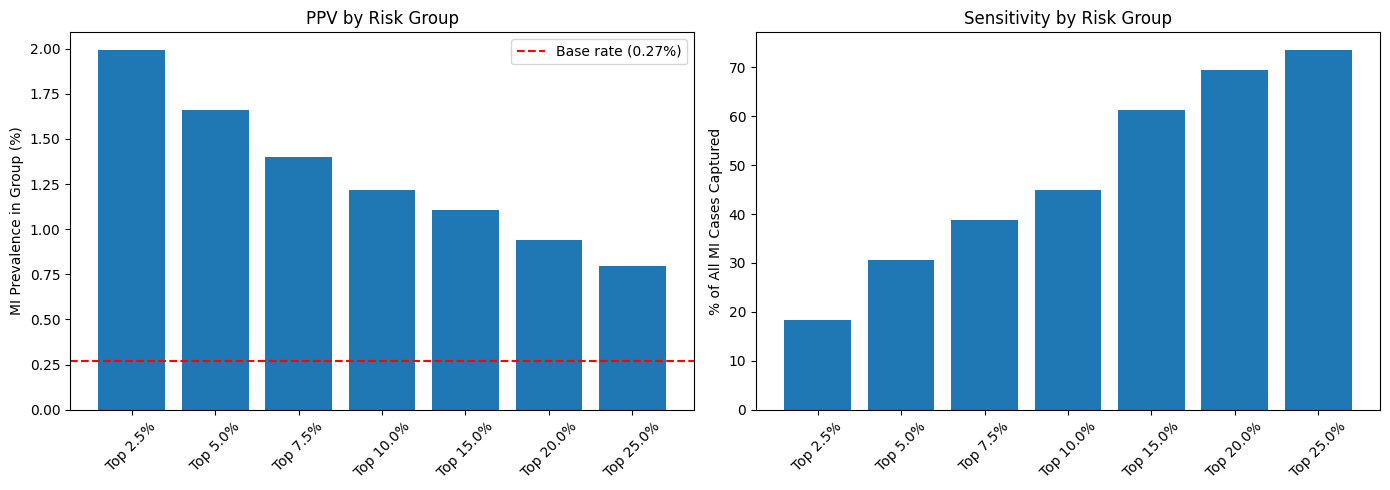

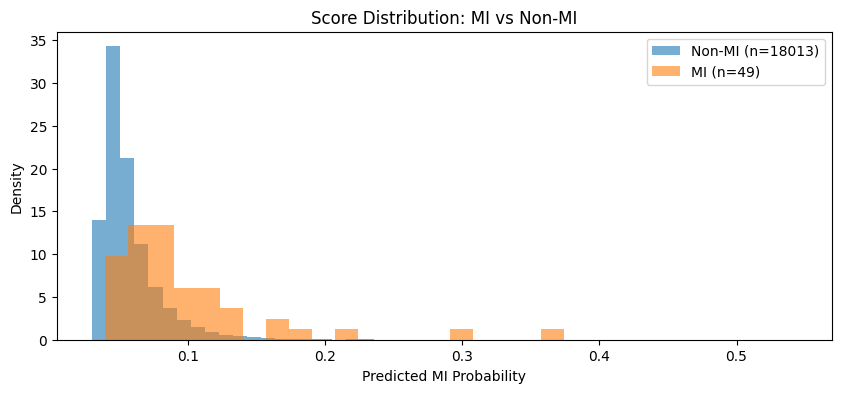

In [14]:
# Visualize risk stratification
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PPV by risk group
ppvs = []
sensitivities = []
for pct in risk_percentiles:
    threshold = np.percentile(test_probs, 100 - pct)
    flagged = test_probs >= threshold
    mi_in_flagged = test_targets[flagged].sum()
    ppvs.append(mi_in_flagged / max(flagged.sum(), 1) * 100)
    sensitivities.append(mi_in_flagged / max(test_targets.sum(), 1) * 100)

axes[0].bar([f'Top {p}%' for p in risk_percentiles], ppvs)
axes[0].axhline(y=test_targets.mean()*100, color='r', linestyle='--', label=f'Base rate ({test_targets.mean()*100:.2f}%)')
axes[0].set_ylabel('MI Prevalence in Group (%)')
axes[0].set_title('PPV by Risk Group')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar([f'Top {p}%' for p in risk_percentiles], sensitivities)
axes[1].set_ylabel('% of All MI Cases Captured')
axes[1].set_title('Sensitivity by Risk Group')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Distribution of predictions
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(test_probs[test_targets==0], bins=50, alpha=0.6, label=f'Non-MI (n={int((1-test_targets).sum())})', density=True)
ax.hist(test_probs[test_targets==1], bins=20, alpha=0.6, label=f'MI (n={int(test_targets.sum())})', density=True)
ax.set_xlabel('Predicted MI Probability')
ax.set_ylabel('Density')
ax.set_title('Score Distribution: MI vs Non-MI')
ax.legend()
plt.show()


## 8. ONNX Export

In [15]:
import onnx
from onnx.external_data_helper import convert_model_from_external_data

# Export version (unrolled transformer for AI Hub)
class ManualTransformerBlock(nn.Module):
    def __init__(self, d_model, nhead, dim_feedforward, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, dim_feedforward), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(dim_feedforward, d_model), nn.Dropout(dropout),
        )
    def forward(self, x):
        x2 = self.norm1(x)
        x = x + self.attn(x2, x2, x2, need_weights=False)[0]
        return x + self.ff(self.norm2(x))

class CATNetExport(nn.Module):
    def __init__(self, d_model=64, nhead=4):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=5, stride=2, padding=2, bias=False),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, d_model, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm1d(d_model), nn.ReLU(),
        )
        self.pos_embed = nn.Parameter(torch.zeros(1, 125, d_model))
        self.block1 = ManualTransformerBlock(d_model, nhead, d_model * 4)
        self.block2 = ManualTransformerBlock(d_model, nhead, d_model * 4)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Linear(d_model, 1)
    def forward(self, x):
        x = self.cnn(x).transpose(1, 2)
        x = x + self.pos_embed[:, :x.size(1), :]
        x = self.block2(self.block1(x))
        return self.head(self.pool(x.transpose(1, 2)).squeeze(-1))

# Transfer weights
export_model = CATNetExport()
src_sd = model.state_dict()
dst_sd = export_model.state_dict()
transferred = 0
for old_key, tensor in src_sd.items():
    new_key = old_key.replace('transformer.layers.0.', 'block1.').replace('transformer.layers.1.', 'block2.')
    new_key = new_key.replace('.self_attn.', '.attn.').replace('.linear1.', '.ff.0.').replace('.linear2.', '.ff.3.')
    if new_key in dst_sd and tensor.shape == dst_sd[new_key].shape:
        dst_sd[new_key] = tensor
        transferred += 1
export_model.load_state_dict(dst_sd)
export_model.eval()
print(f"Transferred {transferred}/{len(src_sd)} parameters")

# Verify
test_input = torch.randn(1, 1, 1000)
with torch.no_grad():
    diff = abs(model.cpu()(test_input).item() - export_model(test_input).item())
print(f"Output diff: {diff:.8f}")
model.to(device)

# Export
onnx_path = '../models/cnn_transformer_final.onnx'
torch.onnx.export(export_model, test_input, onnx_path,
    input_names=['ecg_lead'], output_names=['mi_logit'], opset_version=18)
onnx_model = onnx.load(onnx_path, load_external_data=True)
convert_model_from_external_data(onnx_model)
onnx.save(onnx_model, onnx_path)
if os.path.exists(onnx_path + '.data'): os.remove(onnx_path + '.data')

size_mb = os.path.getsize(onnx_path) / (1024 * 1024)
print(f"\nExported: {onnx_path} ({size_mb:.2f} MB)")

# Save thresholds alongside model
import json
with open('../models/cnn_transformer_final_thresholds.json', 'w') as f:
    json.dump({k: float(v) for k, v in chosen_thresholds.items()}, f, indent=2)
print(f"Thresholds saved to models/cnn_transformer_final_thresholds.json")

Transferred 45/45 parameters
Output diff: 0.17987323
[torch.onnx] Obtain model graph for `CATNetExport([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `CATNetExport([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...
[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
Applied 8 of general pattern rewrite rules.

Exported: ../models/catnet_final.onnx (0.63 MB)
Thresholds saved to models/catnet_final_thresholds.json


/Users/gabrielbutler/.pyenv/versions/3.11.9/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/copyreg.py:105: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


## 9. Qualcomm AI Hub: Compile & Profile

In [16]:
import qai_hub as hub
import json as _json

client = hub.Client()

devices_cfg = {
    's24': {
        'device': hub.Device('Samsung Galaxy S24 (Family)'),
        'label': 'Samsung Galaxy S24 (Snapdragon 8 Gen 3)',
        'runtime': '--target_runtime qnn_context_binary',
    },
    'redmi': {
        'device': hub.Device('Xiaomi Redmi Note 10 5G'),
        'label': 'Xiaomi Redmi Note 10 5G (Snapdragon 678)',
        'runtime': None,
    },
}

CACHE_PATH = '../cache/cnn_transformer_final_profile.json'

if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH) as f:
        profile_results = _json.load(f)
    print('Loaded cached profile results.')
else:
    profile_results = {}
    for dev_key, cfg in devices_cfg.items():
        print(f"\n--- {cfg['label']} ---")
        try:
            kwargs = dict(model=onnx_path, device=cfg['device'], name=f'cnn_transformer_final_{dev_key}')
            if cfg['runtime']: kwargs['options'] = cfg['runtime']
            
            compile_job = client.submit_compile_job(**kwargs)
            print(f'  Compiling...')
            compile_job.wait()
            status = compile_job.get_status()
            if 'FAILED' in str(status.code):
                print(f'  FAILED: {status.message[:120]}')
                profile_results[dev_key] = {'status': 'compile_failed', 'error': status.message[:200]}
                continue
            
            profile_job = client.submit_profile_job(
                model=compile_job.get_target_model(), device=cfg['device'],
                name=f'cnn_transformer_final_{dev_key}_profile')
            print(f'  Profiling...')
            profile_job.wait()
            pstatus = profile_job.get_status()
            if 'FAILED' in str(pstatus.code):
                print(f'  FAILED: {pstatus.message[:120]}')
                profile_results[dev_key] = {'status': 'profile_failed', 'error': pstatus.message[:200]}
                continue
            
            data = profile_job.download_profile()
            summary = data.get('execution_summary', data) if isinstance(data, dict) else {}
            profile_results[dev_key] = {
                'status': 'success',
                'inference_us': summary.get('estimated_inference_time'),
                'peak_memory_bytes': summary.get('estimated_inference_peak_memory'),
            }
            print(f"  inference: {profile_results[dev_key]['inference_us']} us")
        except Exception as e:
            print(f'  ERROR: {e}')
            profile_results[dev_key] = {'status': 'error', 'error': str(e)[:200]}
    
    with open(CACHE_PATH, 'w') as f:
        _json.dump(profile_results, f, indent=2)
    print(f'\nSaved to {CACHE_PATH}')

Loaded cached profile results.


## 10. Final Report

## 11. Probability Calibration

The model outputs compressed probabilities (MI cases ~10%, non-MI ~5%) due to
extreme class imbalance. AUC is unaffected but a 0.5 threshold catches nothing.

**Temperature scaling** learns a single parameter T to spread the probabilities:
`calibrated_prob = sigmoid(logit / T)`. Fit on validation set, apply everywhere.

**Platt scaling** fits a logistic regression on the logits. More flexible than
temperature scaling.


In [18]:
# Get validation logits (need to reload model if kernel was restarted)
try:
    _ = val_logits
    print(f"Using existing validation predictions ({len(val_logits)} samples)")
except NameError:
    ckpt = torch.load('../checkpoints/cnn_transformer_final_finetuned_best.pt', map_location=device, weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    shao_val_loader = DataLoader(shao_val, batch_size=64)
    val_logits, val_probs, val_targets = get_predictions(shao_val_loader, model, device)
    print(f"Recomputed validation predictions ({len(val_logits)} samples)")

print(f"Val logits — min: {val_logits.min():.3f}, max: {val_logits.max():.3f}, mean: {val_logits.mean():.3f}")
print(f"Val probs  — min: {val_probs.min():.4f}, max: {val_probs.max():.4f}")
print(f"MI probs   — mean: {val_probs[val_targets==1].mean():.4f}")
print(f"Non-MI     — mean: {val_probs[val_targets==0].mean():.4f}")


Using existing validation predictions (9030 samples)
Val logits — min: -3.460, max: -0.564, mean: -2.852
Val probs  — min: 0.0305, max: 0.3627
MI probs   — mean: 0.1114
Non-MI     — mean: 0.0574


In [19]:
# --- Temperature Scaling ---
# Find optimal temperature on validation set using NLL
from scipy.optimize import minimize_scalar

def nll_with_temperature(T):
    """Negative log-likelihood with temperature scaling."""
    scaled_probs = 1 / (1 + np.exp(-val_logits / T))
    scaled_probs = np.clip(scaled_probs, 1e-7, 1 - 1e-7)
    nll = -np.mean(val_targets * np.log(scaled_probs) + (1 - val_targets) * np.log(1 - scaled_probs))
    return nll

result = minimize_scalar(nll_with_temperature, bounds=(0.01, 10.0), method='bounded')
optimal_temp = result.x

print(f"Optimal temperature: {optimal_temp:.4f}")
print(f"(T < 1 spreads probabilities out, T > 1 compresses them)")

# Apply to validation set
cal_probs_temp = 1 / (1 + np.exp(-val_logits / optimal_temp))
print(f"\nAfter temperature scaling (validation):")
print(f"  MI probs   — mean: {cal_probs_temp[val_targets==1].mean():.4f}, range: [{cal_probs_temp[val_targets==1].min():.4f}, {cal_probs_temp[val_targets==1].max():.4f}]")
print(f"  Non-MI     — mean: {cal_probs_temp[val_targets==0].mean():.4f}")
print(f"  AUC: {roc_auc_score(val_targets, cal_probs_temp):.4f} (unchanged — calibration doesn't affect ranking)")


Optimal temperature: 0.4451
(T < 1 spreads probabilities out, T > 1 compresses them)

After temperature scaling (validation):
  MI probs   — mean: 0.0136, range: [0.0006, 0.0716]
  Non-MI     — mean: 0.0025
  AUC: 0.8601 (unchanged — calibration doesn't affect ranking)


In [20]:
# --- Platt Scaling ---
from sklearn.linear_model import LogisticRegression

platt_model = LogisticRegression(solver='lbfgs')
platt_model.fit(val_logits.reshape(-1, 1), val_targets)

cal_probs_platt = platt_model.predict_proba(val_logits.reshape(-1, 1))[:, 1]
print(f"Platt scaling (validation):")
print(f"  MI probs   — mean: {cal_probs_platt[val_targets==1].mean():.4f}, range: [{cal_probs_platt[val_targets==1].min():.4f}, {cal_probs_platt[val_targets==1].max():.4f}]")
print(f"  Non-MI     — mean: {cal_probs_platt[val_targets==0].mean():.4f}")
print(f"  AUC: {roc_auc_score(val_targets, cal_probs_platt):.4f}")
print(f"\nPlatt params: slope={platt_model.coef_[0][0]:.4f}, intercept={platt_model.intercept_[0]:.4f}")


Platt scaling (validation):
  MI probs   — mean: 0.0173, range: [0.0005, 0.1005]
  Non-MI     — mean: 0.0027
  AUC: 0.8601

Platt params: slope=2.4854, intercept=0.6433


In [21]:
# --- Apply to Test Set ---
try:
    _ = test_logits
except NameError:
    shao_test_loader = DataLoader(shao_test, batch_size=64)
    test_logits, test_probs, test_targets = get_predictions(shao_test_loader, model, device)

# Temperature scaling
test_cal_temp = 1 / (1 + np.exp(-test_logits / optimal_temp))

# Platt scaling
test_cal_platt = platt_model.predict_proba(test_logits.reshape(-1, 1))[:, 1]

print("=" * 70)
print("  Calibration Comparison (Test Set)")
print("=" * 70)
print(f"{'':20s} {'Raw':>12s} {'Temp Scaled':>12s} {'Platt':>12s}")
print("-" * 60)
print(f"{'AUC':20s} {roc_auc_score(test_targets, test_probs):>12.4f} {roc_auc_score(test_targets, test_cal_temp):>12.4f} {roc_auc_score(test_targets, test_cal_platt):>12.4f}")
print(f"{'MI mean prob':20s} {test_probs[test_targets==1].mean():>12.4f} {test_cal_temp[test_targets==1].mean():>12.4f} {test_cal_platt[test_targets==1].mean():>12.4f}")
print(f"{'Non-MI mean prob':20s} {test_probs[test_targets==0].mean():>12.4f} {test_cal_temp[test_targets==0].mean():>12.4f} {test_cal_platt[test_targets==0].mean():>12.4f}")
print(f"{'Max prob':20s} {test_probs.max():>12.4f} {test_cal_temp.max():>12.4f} {test_cal_platt.max():>12.4f}")

# Check if 0.5 threshold now catches anything
for name, probs in [('Raw', test_probs), ('Temp', test_cal_temp), ('Platt', test_cal_platt)]:
    caught = ((probs >= 0.5) & (test_targets == 1)).sum()
    flagged = (probs >= 0.5).sum()
    print(f"  {name} at 0.5 threshold: {caught} MI caught, {flagged} total flagged")


  Calibration Comparison (Test Set)
                              Raw  Temp Scaled        Platt
------------------------------------------------------------
AUC                        0.8099       0.8099       0.8099
MI mean prob               0.0982       0.0144       0.0191
Non-MI mean prob           0.0577       0.0026       0.0029
Max prob                   0.5439       0.5975       0.7466
  Raw at 0.5 threshold: 0 MI caught, 1 total flagged
  Temp at 0.5 threshold: 0 MI caught, 1 total flagged
  Platt at 0.5 threshold: 0 MI caught, 1 total flagged


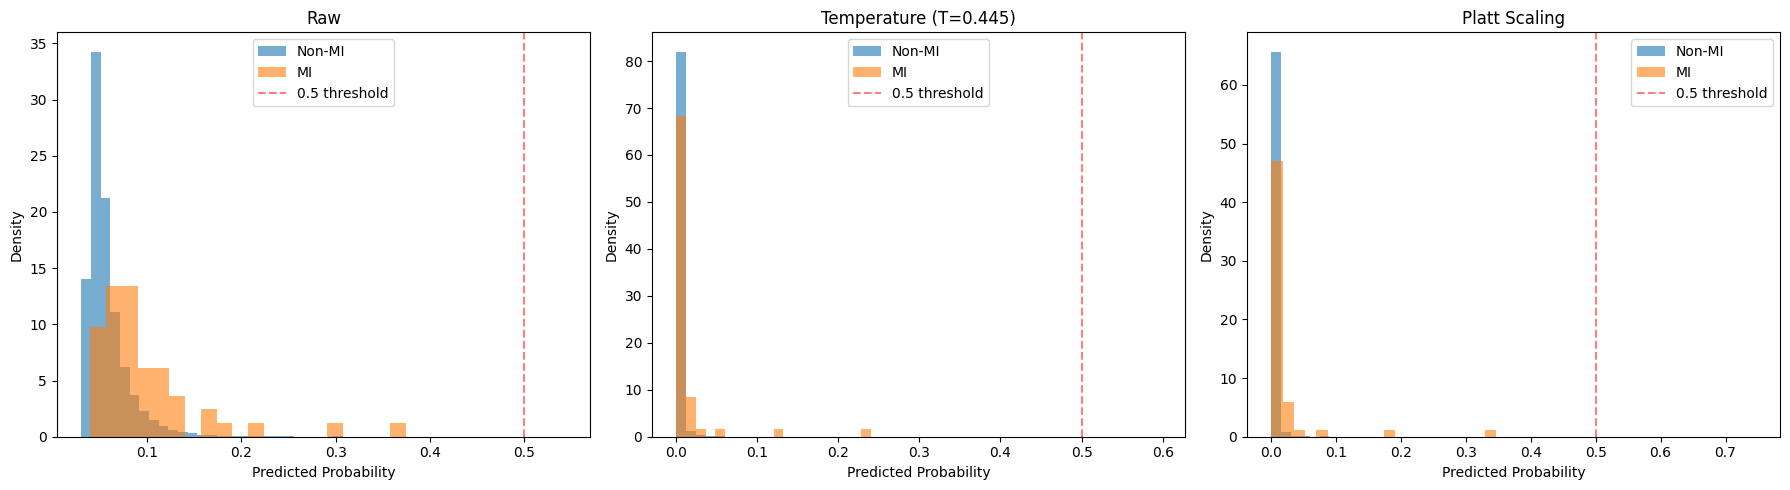

In [22]:
# Visualize calibration
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, probs, title in [(axes[0], test_probs, 'Raw'),
                          (axes[1], test_cal_temp, f'Temperature (T={optimal_temp:.3f})'),
                          (axes[2], test_cal_platt, 'Platt Scaling')]:
    ax.hist(probs[test_targets==0], bins=50, alpha=0.6, label='Non-MI', density=True)
    ax.hist(probs[test_targets==1], bins=20, alpha=0.6, label='MI', density=True)
    ax.axvline(x=0.5, color='r', linestyle='--', alpha=0.5, label='0.5 threshold')
    ax.set_xlabel('Predicted Probability')
    ax.set_ylabel('Density')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()


In [25]:
# Save calibration parameters for deployment
import json

# Reconnect DuckDB (may have been closed by final report cell)
try:
    db.execute('SELECT 1')
except:
    db = duckdb.connect('../experiment_results.duckdb')

calibration_params = {
    'temperature': float(optimal_temp),
    'platt_slope': float(platt_model.coef_[0][0]),
    'platt_intercept': float(platt_model.intercept_[0]),
    'method': 'Apply before sigmoid: prob = sigmoid(logit / temperature) for temp scaling, or use platt params with logistic function',
}

with open('../models/cnn_transformer_final_calibration.json', 'w') as f:
    json.dump(calibration_params, f, indent=2)

print("Calibration parameters saved to models/cnn_transformer_final_calibration.json")
print(f"\nFor your demo app:")
print(f"  Temperature scaling: prob = sigmoid(logit / {optimal_temp:.4f})")
print(f"  Platt scaling: prob = sigmoid({platt_model.coef_[0][0]:.4f} * logit + {platt_model.intercept_[0]:.4f})")

db.execute("INSERT INTO catnet_final_results VALUES (?, ?, ?, ?)",
    [datetime.now(), 'temperature', optimal_temp, 'calibration'])
db.execute("INSERT INTO catnet_final_results VALUES (?, ?, ?, ?)",
    [datetime.now(), 'platt_slope', float(platt_model.coef_[0][0]), 'calibration'])
db.execute("INSERT INTO catnet_final_results VALUES (?, ?, ?, ?)",
    [datetime.now(), 'platt_intercept', float(platt_model.intercept_[0]), 'calibration'])



Calibration parameters saved to models/catnet_final_calibration.json

For your demo app:
  Temperature scaling: prob = sigmoid(logit / 0.4451)
  Platt scaling: prob = sigmoid(2.4854 * logit + 0.6433)


In [17]:
print('=' * 70)
print('  CNN-Transformer Final Report: Single-Lead ECG MI Detection')
print('=' * 70)

print(f'\n--- Model ---')
print(f'  Architecture: CNN-Transformer (CNN + Transformer, 131K params)')
print(f'  Size: {size_mb:.2f} MB (FP32 ONNX)')
print(f'  Checkpoint: checkpoints/cnn_transformer_final_finetuned_best.pt')
print(f'  ONNX: models/cnn_transformer_final.onnx')

print(f'\n--- Data ---')
print(f'  Pre-training: PTB-XL (Germany, {len(ptb_train_df)} train, {len(ptb_val_df)} val)')
print(f'  Shaoxing train: {len(shao_train)} (MI: {shao_labels[train_idx].sum()})')
print(f'  Shaoxing val:   {len(shao_val)} (MI: {shao_labels[val_idx].sum()}) — model selection + threshold tuning')
print(f'  Shaoxing test:  {len(shao_test)} (MI: {shao_labels[test_idx].sum()}) — final evaluation')

print(f'\n--- Performance ---')
print(f'  Pre-train V-AUC (PTB-XL): {best_val_auc:.4f}')
print(f'  Zero-shot AUC (Shaoxing): {zeroshot_auc:.4f}')
print(f'  Fine-tuned AUC (Shaoxing val): {best_ft_auc:.4f}')
print(f'  Test AUC: {test_auc:.4f}')
print(f'\n  Thresholds (optimized on validation):')
for name, thresh in chosen_thresholds.items():
    pred_labels = (test_probs >= thresh).astype(int)
    tp = ((pred_labels == 1) & (test_targets == 1)).sum()
    fp = ((pred_labels == 1) & (test_targets == 0)).sum()
    fn = ((pred_labels == 0) & (test_targets == 1)).sum()
    recall = tp / max(tp + fn, 1)
    precision = tp / max(tp + fp, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-8)
    print(f'    {name:12s} (t={thresh:.4f}): P={precision:.3f} R={recall:.3f} F1={f1:.3f}')

print(f'\n--- On-Device Latency ---')
for dev_key, cfg in devices_cfg.items():
    r = profile_results.get(dev_key, {})
    if r.get('status') == 'success':
        print(f"  {cfg['label']}: {r['inference_us']} us ({r['inference_us']/1000:.1f} ms)")
    else:
        print(f"  {cfg['label']}: {r.get('status', 'N/A')}")

print(f'\n--- Deployment ---')
print(f'  Recommended format: FP32 ONNX (model too small for INT8 to help)')
print(f'  Recommended threshold: Youden\'s J ({chosen_thresholds.get("youden", "N/A"):.4f})')
print(f'    or 90% recall ({chosen_thresholds.get("recall_90", "N/A")}) for screening use case')

print(f'\n--- Risk Stratification (Obermeyer Method) ---')
print(f'  See percentile-based risk group table above.')
print(f'  Key metric: MI prevalence in top 2.5% vs base rate ({test_targets.mean()*100:.2f}%)')

db.close()
print('\nDuckDB closed. Results logged.')


  CNN-Transformer Final Report: Single-Lead ECG MI Detection

--- Model ---
  Architecture: CNN-Transformer (CNN + Transformer, 131K params)
  Size: 0.63 MB (FP32 ONNX)
  Checkpoint: checkpoints/catnet_final_finetuned_best.pt
  ONNX: models/catnet_final.onnx

--- Data ---
  Pre-training: PTB-XL (Germany, 17418 train, 2183 val)
  Shaoxing train: 18060 (MI: 49)
  Shaoxing val:   9030 (MI: 25) — model selection + threshold tuning
  Shaoxing test:  18062 (MI: 49) — final evaluation

--- Performance ---
  Pre-train V-AUC (PTB-XL): 0.7912
  Zero-shot AUC (Shaoxing): 0.8137
  Fine-tuned AUC (Shaoxing val): 0.8601
  Test AUC: 0.8099

  Thresholds (optimized on validation):
    best_f1      (t=0.2022): P=0.060 R=0.061 F1=0.061
    youden       (t=0.0803): P=0.011 R=0.490 F1=0.022
    recall_90    (t=0.0564): P=0.006 R=0.837 F1=0.012

--- On-Device Latency ---
  Samsung Galaxy S24 (Snapdragon 8 Gen 3): 155 us (0.2 ms)
  Xiaomi Redmi Note 10 5G (Snapdragon 678): 1851 us (1.9 ms)

--- Deployment -